# A - Explore vegetation occurrences (A1-A4)
Run top to bottom. Every cell is one step; the helper functions are in `helpers.py`.

In [1]:
import sys; sys.path.insert(0, "..")            # so the notebook finds helpers.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import helpers as H

EP = H.epochs()                                  # all epochs found in data/merged
R = {e: H.process(e) for e in EP}                # ground / vegetation separation: slow the first time, cached afterwards
print([H.EPOCH_LABEL[e] for e in EP])
E = "20250327" if "20250327" in EP else EP[-1]       # epoch used for the examples (the date of the manual biomass samples)

['Feb 2024', 'May 2024', 'Jun 2024', 'Jul 2024', 'Mar 2025', 'May 2025', 'Feb 2026', 'Oct 2026']


## A1 - Point cloud characteristics (and the effect of point density)

In [2]:
a1 = H.describe_files(EP); H.table(a1, "A1_characteristics")

,epoch,points,x range (m),y range (m),z range (m),density (pts/m2),spacing (cm),has RGB
0,Feb 2024,43296293,72290-72510,451410-451640,2.16-9.16,855.7,3.4,True
1,May 2024,65886474,72290-72510,451410-451640,2.07-12.64,1302.1,2.8,True
2,Jun 2024,65496455,72290-72510,451410-451640,2.02-18.96,1294.4,2.8,True
3,Jul 2024,52696020,72290-72510,451410-451640,1.79-18.33,1041.4,3.1,True
4,Mar 2025,30173644,72290-72510,451410-451640,1.96-12.59,596.3,4.1,True
5,May 2025,29044384,72290-72510,451410-451640,1.96-12.62,574.0,4.2,True
6,Feb 2026,30206862,72290-72510,451410-451640,1.67-12.60,597.0,4.1,True
7,Oct 2026,32209292,72290-72510,451410-451640,1.65-12.52,636.5,4.0,True


Detection of low vegetation depends on density. Test: the same 60 x 60 m window of the densest epoch, thinned to different densities (the merged files keep at most 400 pts/m2).

In [3]:
e_dense = EP[int(a1["density (pts/m2)"].idxmax())]
b = H.blocks(R[e_dense]); best = b.loc[b.cover_m2.idxmax()]                      # window with most vegetation
win = (best.x - 30, best.y - 30, best.x + 30, best.y + 30); rows = []
for dens in [30, 60, 125, 250, 400]:           # 400 = the maximum kept by prepare_data.py
    res = H.separate(H.read_points(e_dense, density=dens, box=win))
    rows.append({"density (pts/m2)": dens, "vegetation points": res["n_veg"], "vegetation cover (m2)": round(H.cover_m2(res), 1)})
H.table(pd.DataFrame(rows), "A1_density_experiment")

[0] Configuring terrain...
[0]  - bbMin: 72477.5 -4.715 451588
[0]  - bbMax: 72510 -2.292 451640
[0] Configuring cloth...
[0]  - width: 69 height: 109
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...


[0] Configuring terrain...
[0]  - bbMin: 72477.5 -4.74 451588
[0]  - bbMax: 72510 -2.292 451640
[0] Configuring cloth...
[0]  - width: 69 height: 109
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...


[0] Configuring terrain...
[0]  - bbMin: 72477.5 -4.74 451588
[0]  - bbMax: 72510 -2.292 451640
[0] Configuring cloth...
[0]  - width: 69 height: 109
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...


[0] Configuring terrain...
[0]  - bbMin: 72477.5 -4.74 451588
[0]  - bbMax: 72510 -2.292 451640
[0] Configuring cloth...
[0]  - width: 69 height: 109
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...


[0] Configuring terrain...
[0]  - bbMin: 72477.5 -4.74 451588
[0]  - bbMax: 72510 -2.292 451640
[0] Configuring cloth...
[0]  - width: 69 height: 109
[0] Rasterizing...
[0] Simulating...
[0]  - post handle...


,density (pts/m2),vegetation points,vegetation cover (m2)
0,30,3220,10.8
1,60,7003,32.1
2,125,13962,65.9
3,250,18811,83.8
4,400,18811,83.8


**To write (A1):** compare the epochs (points, density, extent, attributes) and discuss the experiment above: at low density small and low plants are missed, so cover is a lower bound and epochs must be compared at the same density (that is why every epoch is thinned to 250 pts/m2).

## A2 - Three vegetation examples and bare sand
Top: canopy height (m). Bottom: the points with their real RGB colour.

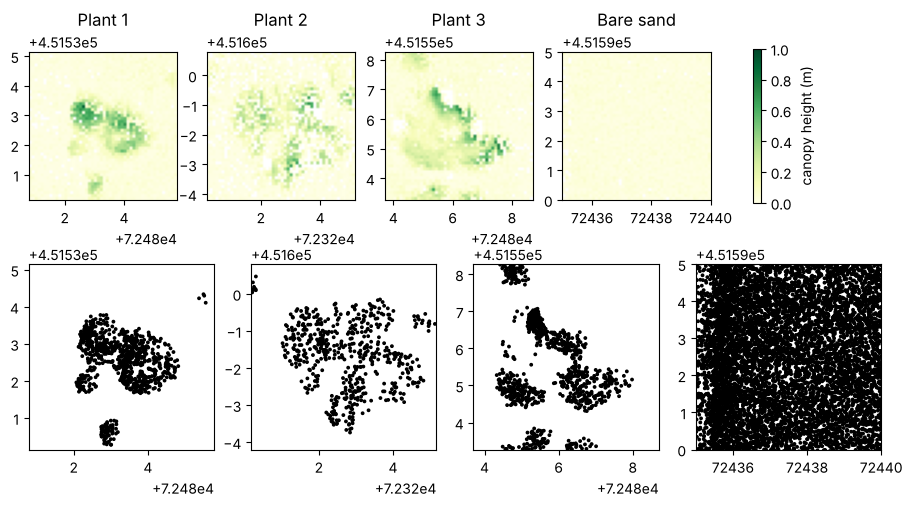

In [4]:
t = H.tussocks(R[E]); top = t.sort_values("vol_column", ascending=False).head(3).reset_index(drop=True)
bl = H.blocks(R[E], t); sand = bl[(bl.cover_m2 == 0) & (bl.slope_deg < 5) & (bl.data_share > .95)].sort_values("slope_deg").iloc[0]
spots = [(r.x, r.y, f"Plant {i+1}") for i, r in top.iterrows()] + [(sand.x, sand.y, "Bare sand")]
gf = R[E]["grid_fine"]; v = R[E]["veg"]; h = 2.5
sand_pts = H.read_points(E, box=(sand.x - 5, sand.y - 5, sand.x + 5, sand.y + 5))
fig, axs = plt.subplots(2, 4, figsize=(11, 5.5))
for j, (x, y, name) in enumerate(spots):
    c0, c1 = int((x - h - gf["x0"]) / gf["res"]), int((x + h - gf["x0"]) / gf["res"]); r0, r1 = int((gf["y1"] - y - h) / gf["res"]), int((gf["y1"] - y + h) / gf["res"])
    im = axs[0, j].imshow(R[E]["chm"][r0:r1, c0:c1], extent=(x-h, x+h, y-h, y+h), vmin=0, vmax=1, cmap="YlGn"); axs[0, j].set_title(name)
    if name == "Bare sand": p = sand_pts; xx, yy, cc = p["x"], p["y"], p["rgb"]
    else: m = (abs(v["x"] - x) < h) & (abs(v["y"] - y) < h); xx, yy, cc = v["x"][m], v["y"][m], v["rgb"][m]
    axs[1, j].scatter(xx, yy, c=np.clip(cc, 0, 1), s=3); axs[1, j].set_xlim(x-h, x+h); axs[1, j].set_ylim(y-h, y+h); axs[1, j].set_aspect("equal")
fig.colorbar(im, ax=axs[0, :], label="canopy height (m)", shrink=.8); H.save(fig, "A2_patches")

In [5]:
sb, sx = sand_pts["rgb"].mean(1), 2 * sand_pts["rgb"][:, 1] - sand_pts["rgb"][:, 0] - sand_pts["rgb"][:, 2]
H.table(pd.concat([
    top[["x", "y", "n_pts", "footprint_m2", "h_max", "h_p95", "vol_column", "linearity", "planarity", "sphericity", "brightness", "exg"]].round(3).assign(patch=["Plant 1", "Plant 2", "Plant 3"]),
    pd.DataFrame([{"patch": "Bare sand (points)", "brightness": sb.mean(), "exg": sx.mean()}]).round(3)]), "A2_patch_attributes")

,x,y,n_pts,footprint_m2,h_max,h_p95,vol_column,linearity,planarity,sphericity,brightness,exg,patch
0,72483.284,451532.651,819.0,3.14,0.896,0.549,1.008,0.617,0.349,0.034,0.0,0.0,Plant 1
1,72322.671,451598.302,448.0,3.08,0.690,0.438,0.837,0.385,0.603,0.012,0.0,0.0,Plant 2
2,72486.202,451555.773,570.0,2.30,0.764,0.566,0.794,0.901,0.086,0.013,0.0,0.0,Plant 3
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,Bare sand (points)


**To write (A2):** for each plant the most likely type (from height, footprint, shape: tall dense dome vs. low sparse tuft; there are no species labels in the field data, say so). Which attributes helped: height above ground and shape (linearity / planarity) separate plants from sand best; compare brightness / ExG of the plants with the sand in the table (dry vegetation is dark, so greenness alone is weak).

## A3 - One location through time
A 12 x 12 m window around the largest plant, in every epoch (canopy height, m).

,epoch,cover_m2,max_canopy_height_m
0,Feb 2024,4.23,0.77
1,May 2024,11.78,0.96
2,Jun 2024,8.47,0.76
3,Jul 2024,7.40,0.95
4,Mar 2025,10.46,0.90
5,May 2025,7.29,1.16
6,Feb 2026,8.71,0.95
7,Oct 2026,8.44,0.79


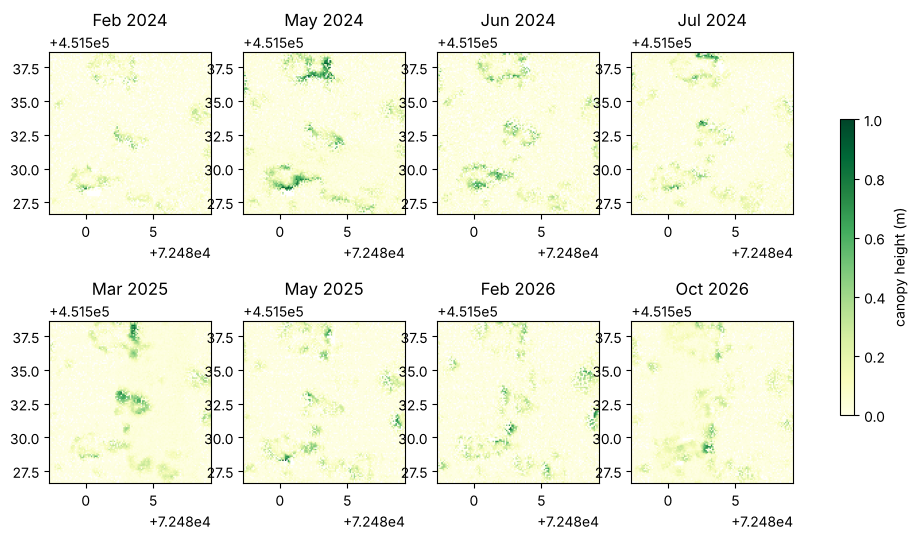

In [6]:
x0, y0 = top.x[0], top.y[0]; h = 6; n = len(EP); cols = 4; fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(12, 3.2 * int(np.ceil(n / cols)))); axs = axs.ravel(); rows = []
for k, e in enumerate(EP):
    g = R[e]["grid_fine"]; c0, c1 = int((x0 - h - g["x0"]) / g["res"]), int((x0 + h - g["x0"]) / g["res"]); r0, r1 = int((g["y1"] - y0 - h) / g["res"]), int((g["y1"] - y0 + h) / g["res"])
    chm = R[e]["chm"][r0:r1, c0:c1]; im = axs[k].imshow(chm, extent=(x0-h, x0+h, y0-h, y0+h), vmin=0, vmax=1, cmap="YlGn"); axs[k].set_title(H.EPOCH_LABEL[e])
    rows.append({"epoch": H.EPOCH_LABEL[e], "cover_m2": round(H.cover(R[e])[r0:r1, c0:c1].sum() * g["res"] ** 2, 2), "max_canopy_height_m": round(float(np.nanmax(chm)), 2)})
for a in axs[n:]: a.axis("off")
fig.colorbar(im, ax=axs, label="canopy height (m)", shrink=.6); H.save(fig, "A3_location_epochs"); H.table(pd.DataFrame(rows), "A3_location_table")

**To write (A3):** what changed and why (season, burial / erosion, different conditions or density during acquisition). Only ground changes bigger than the level of detection (notebook C) are real.

## A4 - Method to separate vegetation from sand
1. **Remove low outliers** (points far below their neighbours pull the cloth down).
2. **Cloth Simulation Filter (CSF)**: coarse ground + non-ground candidates; few parameters, works on slopes.
3. **DTM** from the ground points (median per 25 cm cell).
4. A candidate is **vegetation** if it is **10 cm - 1.5 m above the DTM** (10 cm = about 3 x the 3 cm noise of bare sand; slightly more on slopes) **and not flat** (eigenvalue shape: planarity < 0.65 and linearity / sphericity high enough). Plant points are 3D, sand ripples are planar.
5. Final DTM from everything that is not vegetation; gates repeated.

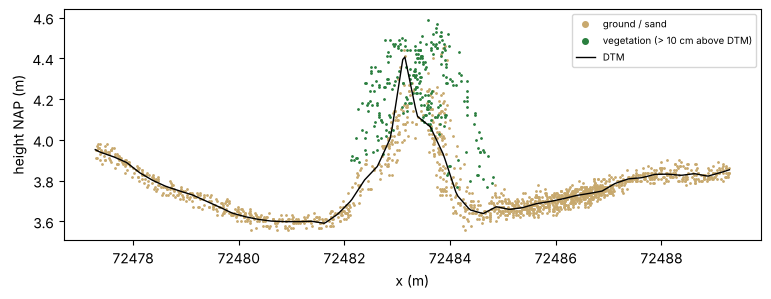

In [7]:
pts = H.read_points(E, box=(x0 - 6, y0 - 0.3, x0 + 6, y0 + 0.3)); hag = pts["z"] - H.sample(R[E]["dtm"], R[E]["grid_dtm"], pts["x"], pts["y"])
fig, ax = plt.subplots(figsize=(9, 3)); isv = (hag >= H.H_MIN) & (hag <= H.H_MAX)
ax.plot(pts["x"][~isv], pts["z"][~isv], ".", c="#c8a96e", ms=2, label="ground / sand"); ax.plot(pts["x"][isv], pts["z"][isv], ".", c="#2a7f3f", ms=2, label="vegetation (> 10 cm above DTM)")
xs = np.linspace(x0 - 6, x0 + 6, 300); ax.plot(xs, H.sample(R[E]["dtm"], R[E]["grid_dtm"], xs, np.full_like(xs, y0)), "k-", lw=1, label="DTM")
ax.set_xlabel("x (m)"); ax.set_ylabel("height NAP (m)"); ax.legend(markerscale=4, fontsize=7); H.save(fig, "A4_profile")

**To write (A4):** why this method given the dataset: sparse low vegetation and noise of 3 cm (so a 10 cm gate), slopes (so CSF + slope-aware gate instead of one global height threshold), 250 pts/m2 (so neighbourhood shape from a 20 cm radius). Validation: the GNSS check of the ground model (separate field data) and the biomass samples (notebook C).